In [2]:
# Baseline simulations using ERA5 and MERRA with Penman–Monteith and Hamon ET0

import pandas as pd
import numpy as np
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from Alfalfa_Irrigation_Model import full_alfalfa_simulation
cutting_rows = []
wp_2013 = {
    0: 19.6,
    1: 24.5,
    2: 25.0,
    3: 24.3,
    4: 13.2,
    5: 12.6,
    6: 11.4,
    7: 10.2,
    8: 10.2,
    9: 10.2,
    10: 10.2,
    11: 10.2,
    12: 10.2
}
for cutting, wp in wp_2013.items():

    cutting_rows.append({
        "Year": 2013,
        "Cutting": cutting,
        "Water_Productivity": wp,
        "Ky": 1.0
    })
wp_regular_year = {
    1: 10.2,
    2: 10.2,
    3: 10.2,
    4: 24.5,
    5: 25.0,
    6: 24.3,
    7: 13.2,
    8: 12.6,
    9: 11.4,
    10: 10.2,
    11: 10.2,
    12: 10.2
}
for year in [2014, 2015, 2016]:
    for cutting, wp in wp_regular_year.items():

        cutting_rows.append({
            "Year": year,
            "Cutting": cutting,
            "Water_Productivity": wp,
            "Ky": 1.0
        })

cutting_param_df = pd.DataFrame(
    cutting_rows
)
stage_lengths = {
    0: [40, 40, 60, 40],
    1: [5, 10, 10, 5],
    2: [5, 10, 10, 5],
    3: [5, 10, 10, 5],
    4: [5, 10, 10, 5],
    5: [5, 10, 10, 5],
    6: [5, 10, 10, 5],
    7: [5, 10, 10, 5],
    8: [5, 10, 10, 5],
    9: [5, 10, 10, 5],
    10: [5, 10, 10, 5],
    11: [5, 10, 10, 5],
    12: [5, 10, 10, 5]
}
MAX_IRRIGATION_PER_DAY = 25.0
climate_files = {
    "ERA5":
        "../Input/ImperialCounty_ERA5_DailyClimate_2012_2016.csv",

    "MERRA":
        "../Input/ImperialCounty_MERRA_DailyClimate_2012_2016.csv"
}
et0_methods = [
    "penman",
    "hamon"
]

all_annual_yield = []
all_annual_water = []
simulation_results = {}

for climate_name, climate_file in climate_files.items():
    df_climate = pd.read_csv(
        climate_file,
        parse_dates=["Date"]
    )
    df_climate.set_index(
        "Date",
        inplace=True
    )
    df_climate.index = pd.to_datetime(
        df_climate.index
    )
    df_climate.sort_index(
        inplace=True
    )
    df_climate.index.name = "Date"
    print("\n")
    print("=" * 90)
    print(
        f"CLIMATE DATASET: {climate_name}"
    )
    print("=" * 90)
    print(
        f"Climate period: "
        f"{df_climate.index.min().date()} "
        f"to "
        f"{df_climate.index.max().date()}"
    )
    print(
        f"Number of rows: "
        f"{len(df_climate)}"
    )
    for et0_method in et0_methods:
        print("\n")
        print("-" * 90)
        print(
            f"RUNNING: "
            f"{climate_name} + "
            f"{et0_method.upper()}"
        )
        print("-" * 90)
        df_result, df_cuttings, df_yearly = (
            full_alfalfa_simulation(
                climate_csv_path=None,
                cutting_param_csv_path=None,
                climate_df=df_climate.copy(),
                cutting_param_df=cutting_param_df.copy(),
                output_csv_path=None,
                cutting_yield_output_csv_path=None,
                yearly_yield_output_csv_path=None,
                start_date="2012-10-15",
                years=[
                    2012,
                    2013,
                    2014,
                    2015,
                    2016
                ],
                et0_method=et0_method,
                cutting_kc=[
                    0.4,
                    0.4,
                    1.2,
                    1.2,
                    1.15
                ],
                kc_dormant=0.35,
                kc_harvest_day=0.15,
                kc_post_harvest=0.25,
                kc_pre_harvest_factor=0.6,
                root_depth_mm=1200,
                awc_mm_per_mm=0.12,
                p_depletion=0.5,
                initial_smt_fraction=0.7,
                MAD=0.3,
                refill_target_fraction=1.0,
                survival_threshold_fraction=0.3,
                max_irrigation_per_day=(
                    MAX_IRRIGATION_PER_DAY
                ),
                min_infiltration=8,
                use_infiltration_excess=True,
                soil_params={
                    "theta_s": 0.4427281,
                    "theta_r": 0.1469845,
                    "n": 1.170828,
                    "K_sat": 1.836049,
                    "pwp": 0.14
                },
                temperature_dormancy_threshold=6,
                pre_harvest_no_irrigation_days=3,
                post_cutting_buffer_days=5,
                yield_min_cutting=0.5,
                min_establishment_days=180,
                stage_lengths_by_cutting_number=(
                    stage_lengths
                ),
                establishment_cutting=0,
                di_levers={
                    "DI_establishment": 1.0,
                    "DI_winter": 1.0,
                    "DI_spring": 1.0,
                    "DI_summer": 1.0,
                    "DI_fall": 1.0
                }
            )
        )
        simulation_results[
            (climate_name, et0_method)
        ] = {

            "daily":
                df_result.copy(),

            "cuttings":
                df_cuttings.copy(),

            "yearly":
                df_yearly.copy()
        }
        annual_yield = df_yearly[
            [
                "Year",
                "Total_Yield_Mg_ha_WP",
                "Total_Yield_Mg_ha_Ky",
                "Total_Yield_Mg_ha_Mitsch"
            ]
        ].copy()
        annual_yield.insert(
            0,
            "ET0_Method",
            et0_method.capitalize()
        )
        annual_yield.insert(
            0,
            "Climate",
            climate_name
        )
        all_annual_yield.append(
            annual_yield
        )
        df_water = df_result.copy()

        df_water["Year"] = (
            df_water.index.year
        )
        annual_water = (
            df_water
            .groupby("Year")
            .agg(

                Total_Irrigation_mm=(
                    "Irrigation_mm",
                    "sum"
                ),

                Total_AETc_mm=(
                    "AETc",
                    "sum"
                ),

                Total_PETc_mm=(
                    "PETc",
                    "sum"
                )
            )
            .reset_index()
        )
        annual_water.insert(
            0,
            "ET0_Method",
            et0_method.capitalize()
        )

        annual_water.insert(
            0,
            "Climate",
            climate_name
        )
        all_annual_water.append(
            annual_water
        )
annual_yield_comparison = pd.concat(
    all_annual_yield,
    ignore_index=True
)

annual_water_comparison = pd.concat(
    all_annual_water,
    ignore_index=True
)
yield_cols = [
    "Total_Yield_Mg_ha_WP",
    "Total_Yield_Mg_ha_Ky",
    "Total_Yield_Mg_ha_Mitsch"
]
water_cols = [
    "Total_Irrigation_mm",
    "Total_AETc_mm",
    "Total_PETc_mm"
]
annual_yield_display = (
    annual_yield_comparison.copy()
)
annual_yield_display[
    yield_cols
] = (
    annual_yield_display[
        yield_cols
    ].round(3)
)
annual_water_display = (
    annual_water_comparison.copy()
)
annual_water_display[
    water_cols
] = (
    annual_water_display[
        water_cols
    ].round(3)
)
print("\n")
print("=" * 110)
print(
    "ANNUAL YIELD COMPARISON"
)
print("=" * 110)
print(
    annual_yield_display.to_string(
        index=False
    )
)
print("\n")
print("=" * 110)
print(
    "ANNUAL IRRIGATION, AETc, AND PETc COMPARISON"
)
print("=" * 110)
print(
    annual_water_display.to_string(
        index=False
    )
)



CLIMATE DATASET: ERA5
Climate period: 2012-01-01 to 2016-12-31
Number of rows: 1827


------------------------------------------------------------------------------------------
RUNNING: ERA5 + PENMAN
------------------------------------------------------------------------------------------


------------------------------------------------------------------------------------------
RUNNING: ERA5 + HAMON
------------------------------------------------------------------------------------------


CLIMATE DATASET: MERRA
Climate period: 2012-01-01 to 2016-12-31
Number of rows: 1827


------------------------------------------------------------------------------------------
RUNNING: MERRA + PENMAN
------------------------------------------------------------------------------------------


------------------------------------------------------------------------------------------
RUNNING: MERRA + HAMON
------------------------------------------------------------------------------------------

In [3]:
# Baseline simulation using CIMIS precomputed ET0

import pandas as pd
import numpy as np
from Alfalfa_Irrigation_Model import full_alfalfa_simulation

cimis_path = "../Input/CIMIS_IMPERIAL.csv"
df_cimis_raw = pd.read_csv(cimis_path)
df_cimis_raw["Date"] = pd.to_datetime(
    df_cimis_raw["Date"]
)
df_cimis_raw = (
    df_cimis_raw
    .sort_values("Date")
    .set_index("Date")
)

INCH_TO_MM = 25.4
def F_TO_C(f):
    return (f - 32.0) * (5.0 / 9.0)
climate_df = pd.DataFrame(
    index=df_cimis_raw.index
)
# Precipitation: inches -> mm/day
climate_df["Precip_mm_day"] = (
    pd.to_numeric(
        df_cimis_raw["Precip (in)"],
        errors="coerce"
    )
    * INCH_TO_MM
)
# Temperature: °F -> °C
climate_df["Temperature_C"] = F_TO_C(
    pd.to_numeric(
        df_cimis_raw["Avg Air Temp (F)"],
        errors="coerce"
    )
)
# Precomputed CIMIS ET0: inches -> mm/day
climate_df["ET0"] = (
    pd.to_numeric(
        df_cimis_raw["ETo (in)"],
        errors="coerce"
    )
    * INCH_TO_MM
)
# Approximate Imperial Valley latitude
climate_df["latitude"] = 33.0

climate_df = climate_df[
    (climate_df.index >= "2012-01-01")
    &
    (climate_df.index <= "2016-12-31")
].copy()

climate_df = climate_df.dropna(
    subset=[
        "Precip_mm_day",
        "Temperature_C",
        "ET0"
    ]
)
climate_df.index.name = "Date"
print("=" * 75)
print("CIMIS CLIMATE DATA")
print("=" * 75)
print(
    f"Period: "
    f"{climate_df.index.min().date()} "
    f"to "
    f"{climate_df.index.max().date()}"
)
print(
    f"Number of rows: "
    f"{len(climate_df)}"
)
print("\nFirst rows:")
print(
    climate_df.head()
)

# RUN SIMULATION
df_result_cimis, df_cuttings_cimis, df_yearly_cimis = (
    full_alfalfa_simulation(
        climate_csv_path=None,
        cutting_param_csv_path=None,
        climate_df=climate_df.copy(),
        cutting_param_df=cutting_param_df.copy(),
        output_csv_path=None,
        cutting_yield_output_csv_path=None,
        yearly_yield_output_csv_path=None,
        start_date="2012-10-15",
        years=[
            2012,
            2013,
            2014,
            2015,
            2016
        ],
        # Use ET0 already supplied by CIMIS
        et0_method="precomputed",
        # Crop coefficients
        cutting_kc=[
            0.4,
            0.4,
            1.2,
            1.2,
            1.15
        ],
        kc_dormant=0.35,
        kc_harvest_day=0.15,
        kc_post_harvest=0.25,
        kc_pre_harvest_factor=0.6,
        root_depth_mm=1200,
        awc_mm_per_mm=0.12,
        p_depletion=0.5,
        initial_smt_fraction=0.7,
        MAD=0.3,
        refill_target_fraction=1.0,
        survival_threshold_fraction=0.3,
        max_irrigation_per_day=MAX_IRRIGATION_PER_DAY,
        min_infiltration=8,
        use_infiltration_excess=True,
        soil_params={
            "theta_s": 0.4427281,
            "theta_r": 0.1469845,
            "n": 1.170828,
            "K_sat": 1.836049,
            "pwp": 0.14
        },
        temperature_dormancy_threshold=6,
        pre_harvest_no_irrigation_days=3,
        post_cutting_buffer_days=5,
        yield_min_cutting=0.5,
        min_establishment_days=180,
        stage_lengths_by_cutting_number=stage_lengths,
        establishment_cutting=0,
        di_levers={
            "DI_establishment": 1.0,
            "DI_winter": 1.0,
            "DI_spring": 1.0,
            "DI_summer": 1.0,
            "DI_fall": 1.0
        }
    )
)

print("\n")
print("=" * 90)
print("CIMIS PRECOMPUTED ET0 — ANNUAL YIELD")
print("=" * 90)
annual_yield_cimis = df_yearly_cimis[
    [
        "Year",
        "Total_Yield_Mg_ha_WP",
        "Total_Yield_Mg_ha_Ky",
        "Total_Yield_Mg_ha_Mitsch"
    ]
].copy()
annual_yield_cimis[
    [
        "Total_Yield_Mg_ha_WP",
        "Total_Yield_Mg_ha_Ky",
        "Total_Yield_Mg_ha_Mitsch"
    ]
] = annual_yield_cimis[
    [
        "Total_Yield_Mg_ha_WP",
        "Total_Yield_Mg_ha_Ky",
        "Total_Yield_Mg_ha_Mitsch"
    ]
].round(3)
print(
    annual_yield_cimis.to_string(
        index=False
    )
)

df_water_cimis = df_result_cimis.copy()

df_water_cimis["Year"] = (
    df_water_cimis.index.year
)
annual_water_cimis = (
    df_water_cimis
    .groupby("Year")
    .agg(
        Total_Irrigation_mm=(
            "Irrigation_mm",
            "sum"
        ),
        Total_AETc_mm=(
            "AETc",
            "sum"
        ),
        Total_PETc_mm=(
            "PETc",
            "sum"
        )
    )
    .reset_index()
)
annual_water_cimis[
    [
        "Total_Irrigation_mm",
        "Total_AETc_mm",
        "Total_PETc_mm"
    ]
] = annual_water_cimis[
    [
        "Total_Irrigation_mm",
        "Total_AETc_mm",
        "Total_PETc_mm"
    ]
].round(3)
print("\n")
print("=" * 90)
print("CIMIS PRECOMPUTED ET0 — ANNUAL IRRIGATION AND CROP ET")
print("=" * 90)

print(
    annual_water_cimis.to_string(
        index=False
    )
)

CIMIS CLIMATE DATA
Period: 2012-01-01 to 2016-12-31
Number of rows: 1799

First rows:
            Precip_mm_day  Temperature_C    ET0  latitude
Date                                                     
2012-01-01            0.0      11.222222  2.032      33.0
2012-01-02            0.0      12.500000  2.032      33.0
2012-01-03            0.0      12.722222  2.032      33.0
2012-01-04            0.0      12.611111  2.032      33.0
2012-01-05            0.0      11.444444  1.778      33.0


CIMIS PRECOMPUTED ET0 — ANNUAL YIELD
 Year  Total_Yield_Mg_ha_WP  Total_Yield_Mg_ha_Ky  Total_Yield_Mg_ha_Mitsch
 2013                25.440                25.440                    25.445
 2014                18.671                18.671                    18.686
 2015                19.643                19.643                    19.684
 2016                23.212                23.212                    23.317


CIMIS PRECOMPUTED ET0 — ANNUAL IRRIGATION AND CROP ET
 Year  Total_Irrigation_mm  Total

In [4]:
# Combine ET0, PETc, and AETc from five simulations

import os
import pandas as pd
import numpy as np

dfs = {
    # CIMIS observed/precomputed ET0
    "CIMIS":
        df_result_cimis.copy(),
    # ERA5
    "PM_ERA5":
        simulation_results[
            ("ERA5", "penman")
        ]["daily"].copy(),
    "Hamon_ERA5":
        simulation_results[
            ("ERA5", "hamon")
        ]["daily"].copy(),
    # MERRA
    "PM_MERRA":
        simulation_results[
            ("MERRA", "penman")
        ]["daily"].copy(),
    "Hamon_MERRA":
        simulation_results[
            ("MERRA", "hamon")
        ]["daily"].copy()
}

VARS = [
    "ET0",
    "PETc",
    "AETc"
]

for label, df in dfs.items():
    missing = [
        var
        for var in VARS
        if var not in df.columns
    ]
    if missing:

        raise ValueError(
            f"{label} is missing columns: {missing}\n"
            f"Available columns: {list(df.columns)}"
        )
    df.index = pd.to_datetime(
        df.index
    )
    df.sort_index(
        inplace=True
    )
    df.index.name = "Date"

common_index = None
for df in dfs.values():
    if common_index is None:
        common_index = df.index
    else:
        common_index = (
            common_index
            .intersection(df.index)
        )
common_index = common_index.sort_values()
if len(common_index) == 0:
    raise ValueError(
        "No overlapping dates across the five datasets."
    )
print("=" * 75)
print("COMMON COMPARISON PERIOD")
print("=" * 75)
print(
    f"Start: "
    f"{common_index.min().date()}"
)
print(
    f"End:   "
    f"{common_index.max().date()}"
)

print(
    f"N days: "
    f"{len(common_index)}"
)

dfs_aligned = {

    label:
        df.loc[common_index].copy()

    for label, df in dfs.items()
}

combined = pd.DataFrame(
    index=common_index
)

combined.index.name = "Date"
for label, df in dfs_aligned.items():

    for var in VARS:

        combined[
            f"{var}_{label}"
        ] = pd.to_numeric(
            df[var],
            errors="coerce"
        )

method_order = [
    "CIMIS",
    "PM_ERA5",
    "Hamon_ERA5",
    "PM_MERRA",
    "Hamon_MERRA"
]

ordered_cols = []
for var in VARS:

    for method in method_order:

        ordered_cols.append(
            f"{var}_{method}"
        )
combined = combined[
    ordered_cols
]

print("\n")
print("=" * 75)
print("MISSING VALUES AFTER ALIGNMENT")
print("=" * 75)
print(
    combined
    .isna()
    .sum()
    .to_string()
)
output_dir = "Evaluation_Output"
os.makedirs(
    output_dir,
    exist_ok=True
)
out_path = (
    "Evaluation_Output/"
    "Combined_ET0_PETc_AETc_AllMethods.csv"
)
combined.to_csv(
    out_path
)
print("\n")
print("=" * 75)
print("COMBINED FILE SAVED")
print("=" * 75)

print(
    out_path
)
combined.head()

COMMON COMPARISON PERIOD
Start: 2012-10-15
End:   2016-12-31
N days: 1512


MISSING VALUES AFTER ALIGNMENT
ET0_CIMIS           0
ET0_PM_ERA5         0
ET0_Hamon_ERA5      0
ET0_PM_MERRA        0
ET0_Hamon_MERRA     0
PETc_CIMIS          0
PETc_PM_ERA5        0
PETc_Hamon_ERA5     0
PETc_PM_MERRA       0
PETc_Hamon_MERRA    0
AETc_CIMIS          0
AETc_PM_ERA5        0
AETc_Hamon_ERA5     0
AETc_PM_MERRA       0
AETc_Hamon_MERRA    0


COMBINED FILE SAVED
Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv


,ET0_CIMIS,ET0_PM_ERA5,ET0_Hamon_ERA5,ET0_PM_MERRA,ET0_Hamon_MERRA,PETc_CIMIS,PETc_PM_ERA5,PETc_Hamon_ERA5,PETc_PM_MERRA,PETc_Hamon_MERRA,AETc_CIMIS,AETc_PM_ERA5,AETc_Hamon_ERA5,AETc_PM_MERRA,AETc_Hamon_MERRA
Date,,,,,,,,,,,,,,,
2012-10-15,4.318,5.151907,8.268380,6.157381,7.704503,1.7272,2.060763,3.307352,2.462952,3.081801,1.7272,2.060763,3.307352,2.462952,3.081801
2012-10-16,4.318,3.936326,7.884617,4.491380,8.022154,1.7272,1.574530,3.153847,1.796552,3.208861,1.7272,1.574530,3.153847,1.796552,3.208861
2012-10-17,4.318,2.845535,8.034793,4.045524,8.333455,1.7272,1.138214,3.213917,1.618209,3.333382,1.7272,1.138214,3.213917,1.618209,3.333382
2012-10-18,3.810,3.307126,8.365369,4.322305,7.839994,1.5240,1.322850,3.346148,1.728922,3.135998,1.5240,1.322850,3.346148,1.728922,3.135998
2012-10-19,4.064,3.826276,7.880479,4.644410,7.585265,1.6256,1.530510,3.152192,1.857764,3.034106,1.6256,1.530510,3.152192,1.857764,3.034106


In [5]:
# Table 1. Summary statistics for ET0 across datasets

import pandas as pd
combined = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date")
et0_cols = [
    "ET0_CIMIS",
    "ET0_PM_ERA5",
    "ET0_Hamon_ERA5",
    "ET0_PM_MERRA",
    "ET0_Hamon_MERRA"
]
df_et0 = combined[et0_cols]
stats = df_et0.agg(["mean", "std", "min", "max"]).rename(index={
    "mean": "Mean (mm/day)",
    "std": "Std Dev (mm/day)",
    "min": "Min (mm/day)",
    "max": "Max (mm/day)"
}).round(2)
stats = stats.rename(columns={
    "ET0_CIMIS": "ET0_CIMIS",
    "ET0_PM_ERA5": "PM_ERA5",
    "ET0_Hamon_ERA5": "Hamon_ERA5",
    "ET0_PM_MERRA": "PM_MERRA",
    "ET0_Hamon_MERRA": "Hamon_MERRA"
})
stats

,ET0_CIMIS,PM_ERA5,Hamon_ERA5,PM_MERRA,Hamon_MERRA
Mean (mm/day),4.58,5.18,8.20,5.68,7.87
Std Dev (mm/day),2.24,2.51,4.31,2.66,4.21
Min (mm/day),0.00,0.73,1.85,0.72,1.70
Max (mm/day),11.18,13.41,20.16,14.12,20.57


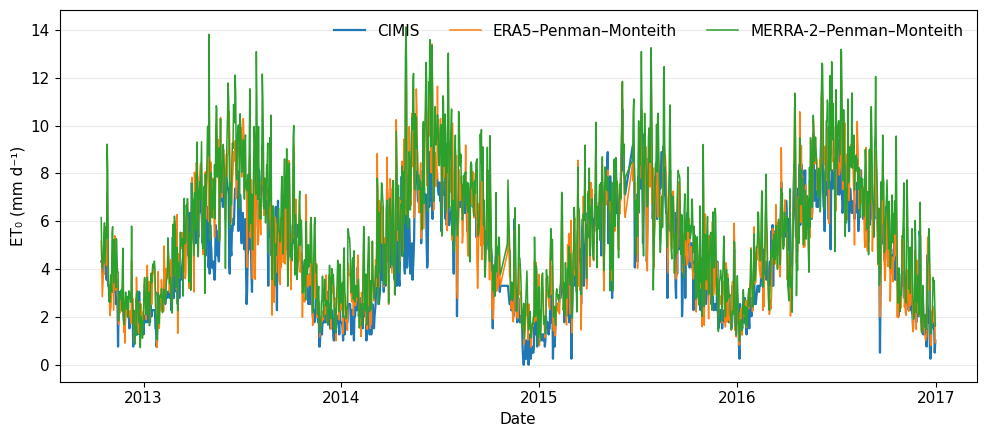

In [6]:
# Figure S1. CIMIS ET0 versus ERA5 and MERRA-2 Penman–Monteith ET0

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11
})

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(df.index, df["ET0_CIMIS"], label="CIMIS", linewidth=1.6)
ax.plot(df.index, df["ET0_PM_ERA5"], label="ERA5–Penman–Monteith", linewidth=1.1)
ax.plot(df.index, df["ET0_PM_MERRA"], label="MERRA-2–Penman–Monteith", linewidth=1.1)

ax.set_xlabel("Date")
ax.set_ylabel("ET₀ (mm d⁻¹)")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.legend(frameon=False, ncol=3)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

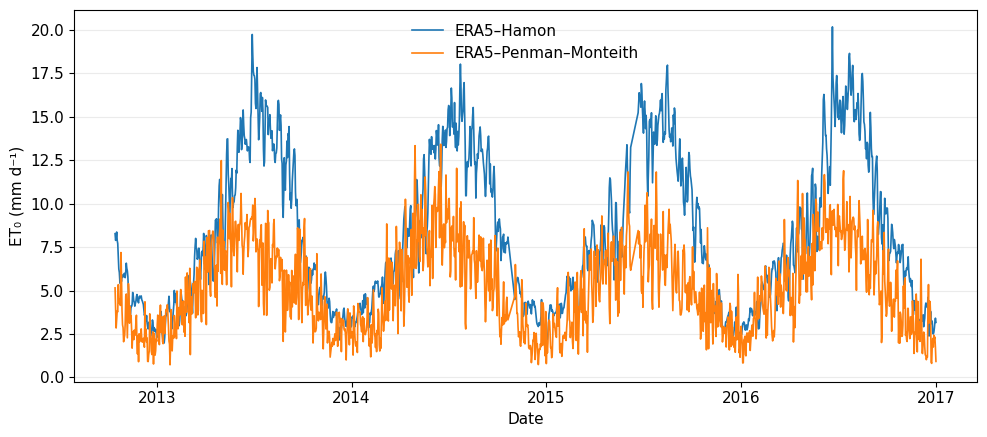

In [7]:
# Figure _S2 Hamon vs Penman-Monteith for ERA5

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11
})

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(df.index, df["ET0_Hamon_ERA5"],
        label="ERA5–Hamon", linewidth=1.2)
ax.plot(df.index, df["ET0_PM_ERA5"],
        label="ERA5–Penman–Monteith", linewidth=1.2)

ax.set_xlabel("Date")
ax.set_ylabel("ET₀ (mm d⁻¹)")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

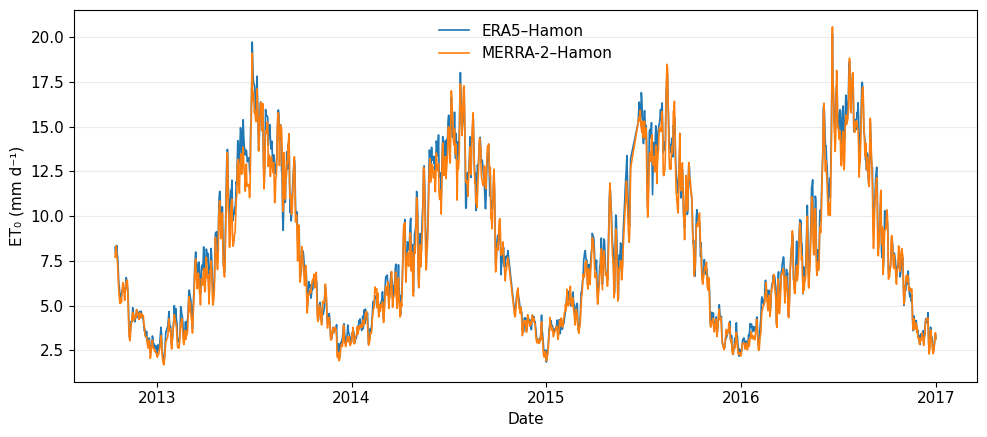

In [8]:
# Figure _S3 Hamon ERA5 vs Hamon MERRA

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11
})

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(df.index, df["ET0_Hamon_ERA5"],
        label="ERA5–Hamon", linewidth=1.2)
ax.plot(df.index, df["ET0_Hamon_MERRA"],
        label="MERRA-2–Hamon", linewidth=1.2)

ax.set_xlabel("Date")
ax.set_ylabel("ET₀ (mm d⁻¹)")

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [9]:
# Table_2: MBE and RMSE of model ET0 vs CIMIS ET0 

import pandas as pd
import numpy as np
df = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()
obs = df["ET0_CIMIS"]
models = {
    "PM_ERA5": "ET0_PM_ERA5",
    "Hamon_ERA5": "ET0_Hamon_ERA5",
    "PM_MERRA": "ET0_PM_MERRA",
    "Hamon_MERRA": "ET0_Hamon_MERRA"
}
results = []
for method, col in models.items():
    model = df[col]
    valid = obs.notna() & model.notna()
    obs_valid = obs[valid]
    model_valid = model[valid]
    mbe = (model_valid - obs_valid).mean()
    rmse = np.sqrt(((model_valid - obs_valid) ** 2).mean())
    results.append({
        "ET₀ Method": method,
        "MBE (mm/day)": round(mbe, 2),
        "RMSE (mm/day)": round(rmse, 2)
    })
error_table = pd.DataFrame(results)
error_table

,ET₀ Method,MBE (mm/day),RMSE (mm/day)
0,PM_ERA5,0.60,1.51
1,Hamon_ERA5,3.62,4.62
2,PM_MERRA,1.09,1.93
3,Hamon_MERRA,3.28,4.37


Evaluation period: 2012-11 to 2016-12
Number of months: 47
CIMIS-driven: RMSE=30.42 mm/month, MAE=23.09 mm/month, MBE=+9.55 mm/month, PBIAS=+9.75%, R²=0.69
ERA5-driven: RMSE=33.73 mm/month, MAE=25.80 mm/month, MBE=+24.47 mm/month, PBIAS=+24.97%, R²=0.79


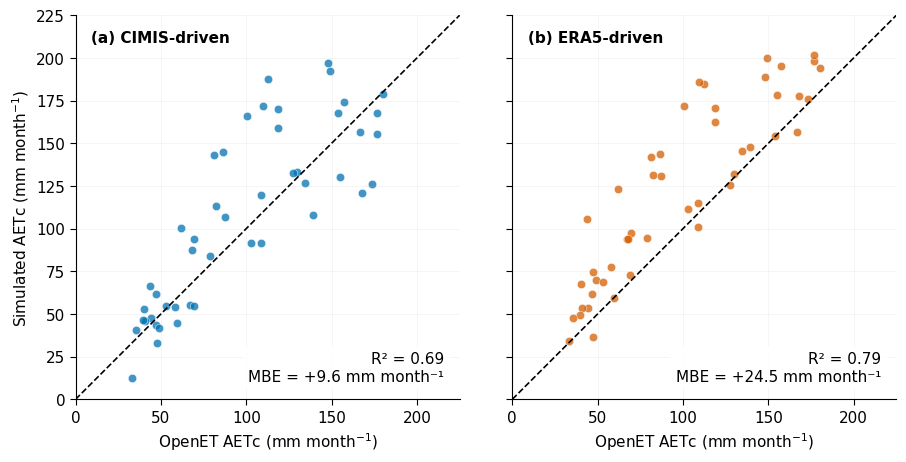

In [12]:
# AETc validation against OpenET
#   1. Table S6 for CIMIS and ERA5
#   2. Figure S7 One two-panel scatter figure

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8
})

model = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()

cols = ["AETc_CIMIS", "AETc_PM_ERA5"]

if model.index.duplicated().any():
    raise ValueError("Duplicate dates found in model output.")

month = model.index.to_period("M")
coverage = model[cols].groupby(month).count()
coverage = coverage.div(coverage.index.days_in_month, axis=0)

complete_months = coverage.index[(coverage >= 0.90).all(axis=1)]

monthly = model[cols].resample("ME").sum(min_count=1)
monthly.index = monthly.index.to_period("M")
monthly = monthly.loc[monthly.index.intersection(complete_months)]

openet = pd.read_csv(
    "Data_To_Validate_With/Imperial_ET_OpenET_Ensemble_2012_2016.csv"
)

openet["Date"] = pd.to_datetime(
    openet["Date"], format="%Y-%m", errors="coerce"
).dt.to_period("M")

openet["AETc_OpenET"] = pd.to_numeric(
    openet["AETc_OpenET"], errors="coerce"
)

openet = openet.dropna(subset=["Date"]).set_index("Date").sort_index()

if openet.index.duplicated().any():
    raise ValueError("Duplicate months found in OpenET data.")

df = monthly.join(openet[["AETc_OpenET"]], how="inner").dropna()
df = df[df.index != pd.Period("2012-10", freq="M")]


def metrics(obs, sim):
    return {
        "RMSE": np.sqrt(mean_squared_error(obs, sim)),
        "MAE": mean_absolute_error(obs, sim),
        "MBE": (sim - obs).mean(),

        # Positive PBIAS = overestimation
        # Negative PBIAS = underestimation
        "PBIAS": (
            100 * (sim - obs).sum() / obs.sum()
            if obs.sum() != 0 else np.nan
        ),

        "R2": pearsonr(obs, sim)[0] ** 2
    }


settings = [
    ("AETc_CIMIS", "CIMIS-driven", "#0072B2"),
    ("AETc_PM_ERA5", "ERA5-driven", "#D55E00")
]


print(f"Evaluation period: {df.index.min()} to {df.index.max()}")
print(f"Number of months: {len(df)}")

for col, label, color in settings:
    m = metrics(df["AETc_OpenET"], df[col])

    print(
        f"{label}: "
        f"RMSE={m['RMSE']:.2f} mm/month, "
        f"MAE={m['MAE']:.2f} mm/month, "
        f"MBE={m['MBE']:+.2f} mm/month, "
        f"PBIAS={m['PBIAS']:+.2f}%, "
        f"R²={m['R2']:.2f}"
    )

limit = np.ceil(
    df[["AETc_OpenET"] + cols].max().max() / 25
) * 25

fig, axes = plt.subplots(
    1, 2, figsize=(9.5, 4.6),
    sharex=True, sharey=True
)

for i, (ax, (col, label, color)) in enumerate(zip(axes, settings)):

    x = df["AETc_OpenET"]
    y = df[col]
    m = metrics(x, y)

    ax.scatter(
        x, y, s=36, color=color,
        alpha=0.75, edgecolor="white", linewidth=0.4
    )

    ax.plot(
        [0, limit], [0, limit],
        color="black", linestyle="--",
        linewidth=1.2, label="1:1 line"
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_aspect("equal", adjustable="box")

    ax.text(
        0.04, 0.96, f"({chr(97+i)}) {label}",
        transform=ax.transAxes,
        ha="left", va="top", fontweight="bold"
    )
    ax.text(
        0.96, 0.04,
        f"R² = {m['R2']:.2f}\n"
        f"MBE = {m['MBE']:+.1f} mm month⁻¹",
        transform=ax.transAxes,
        ha="right", va="bottom",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85
        )
    )

    ax.set_xlabel("OpenET AETc (mm month$^{-1}$)")
    ax.grid(alpha=0.15, linewidth=0.6)
    ax.tick_params(direction="out", length=4, width=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Simulated AETc (mm month$^{-1}$)")

plt.tight_layout()
plt.show()

Months: 47
Period: 2012-11 to 2016-12


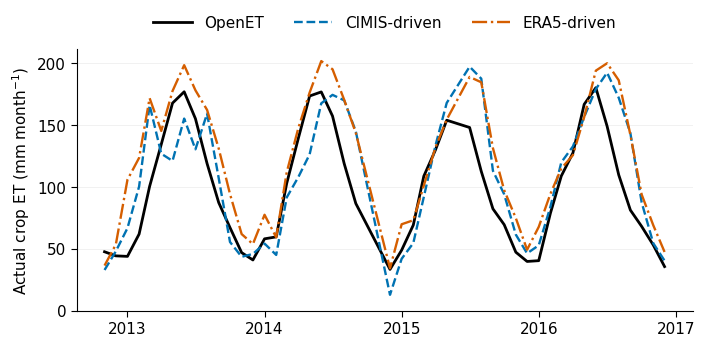

In [12]:
# Fig S6: Monthly AETc Comparison: OpenET vs Simulated Scenarios

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8
})

model_df = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()

month = model_df.index.to_period("M")
model_monthly = model_df.resample("MS").sum(min_count=1)
model_monthly.index = model_monthly.index.to_period("M")

count_col = "ET0_CIMIS" if "ET0_CIMIS" in model_df.columns else model_df.columns[0]
monthly_count = model_df[count_col].groupby(month).count()
days = pd.Series(month.days_in_month, index=month).groupby(level=0).first()

complete_months = monthly_count[monthly_count >= 0.90 * days].index
model_monthly = model_monthly.loc[complete_months]

openet = pd.read_csv(
    "Data_To_Validate_With/Imperial_ET_OpenET_Ensemble_2012_2016.csv"
)
openet["Date"] = pd.to_datetime(
    openet["Date"], format="%Y-%m", errors="coerce"
).dt.to_period("M")

openet = openet.set_index("Date").sort_index()
openet_monthly = pd.to_numeric(openet["AETc_OpenET"], errors="coerce")

common_months = model_monthly.index.intersection(openet_monthly.index)

df = pd.DataFrame({
    "OpenET": openet_monthly.loc[common_months],
    "CIMIS": model_monthly.loc[common_months, "AETc_CIMIS"],
    "ERA5": model_monthly.loc[common_months, "AETc_PM_ERA5"]
}).dropna()

print(f"Months: {len(df)}")
print(f"Period: {df.index.min()} to {df.index.max()}")


fig, ax = plt.subplots(figsize=(7.2, 3.6))

dates = df.index.to_timestamp()

ax.plot(dates, df["OpenET"], color="black",
        linewidth=2.0, label="OpenET")

ax.plot(dates, df["CIMIS"], color="#0072B2",
        linestyle="--", linewidth=1.7, label="CIMIS-driven")

ax.plot(dates, df["ERA5"], color="#D55E00",
        linestyle="-.", linewidth=1.7, label="ERA5-driven")

ax.set_ylabel("Actual crop ET (mm month$^{-1}$)")
ax.set_ylim(bottom=0)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(axis="y", alpha=0.2, linewidth=0.6)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
    columnspacing=2.0,
    handlelength=2.5
)

ax.tick_params(direction="out", length=4, width=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



Evaluation period: 2012-11 to 2015-09
Number of months: 32

Table S7:
Model configuration  RMSE (mm month⁻¹)  MAE (mm month⁻¹)  MBE (mm month⁻¹)  PBIAS (%)   R²
       CIMIS-driven              34.71             29.22            -23.66     -18.02 0.79
        ERA5-driven              20.05             14.39             -2.82      -2.15 0.87


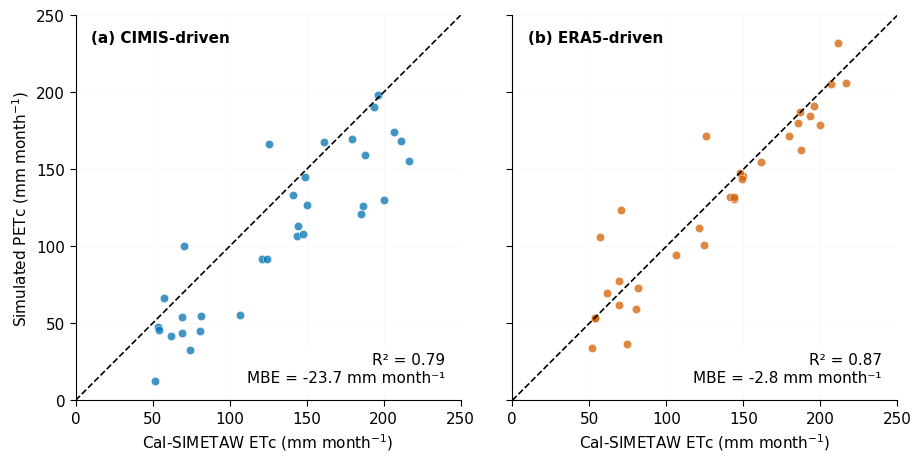

In [14]:
# Table S7 and Fig S9 two-panel Cal-SIMETAW figure

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8
})

model = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()

cols = ["PETc_CIMIS", "PETc_PM_ERA5"]

if model.index.duplicated().any():
    raise ValueError("Duplicate dates found in model output.")

month = model.index.to_period("M")
coverage = model[cols].groupby(month).count()
coverage = coverage.div(coverage.index.days_in_month, axis=0)

complete_months = coverage.index[(coverage >= 0.90).all(axis=1)]

monthly = model[cols].resample("ME").sum(min_count=1)
monthly.index = monthly.index.to_period("M")
monthly = monthly.loc[monthly.index.intersection(complete_months)]

cal = pd.read_csv(
    "Data_To_Validate_With/CAL-SIMETAW_Imperial_monthly.csv"
)

cal["Date"] = pd.to_datetime(cal["Date"], errors="coerce")
cal["Month"] = cal["Date"].dt.to_period("M")
cal["ETc_CalSIMETAW"] = pd.to_numeric(
    cal["ETc_CalSIMETAW"], errors="coerce"
)

cal = cal.dropna(subset=["Month"]).set_index("Month").sort_index()

if cal.index.duplicated().any():
    raise ValueError("Duplicate months found in Cal-SIMETAW data.")

df = monthly.join(cal[["ETc_CalSIMETAW"]], how="inner").dropna()
df = df[df.index != pd.Period("2012-10", freq="M")]


def metrics(obs, sim):
    return {
        "RMSE": np.sqrt(np.mean((sim - obs) ** 2)),
        "MAE": np.mean(np.abs(sim - obs)),
        "MBE": np.mean(sim - obs),

        # Positive bias = overestimation
        # Negative bias = underestimation
        "PBIAS": (
            100 * (sim - obs).sum() / obs.sum()
            if obs.sum() != 0 else np.nan
        ),

        "R2": np.corrcoef(obs, sim)[0, 1] ** 2
    }


settings = [
    ("PETc_CIMIS", "CIMIS-driven", "#0072B2"),
    ("PETc_PM_ERA5", "ERA5-driven", "#D55E00")
]

print(f"Evaluation period: {df.index.min()} to {df.index.max()}")
print(f"Number of months: {len(df)}")


rows = []

for col, label, color in settings:
    m = metrics(df["ETc_CalSIMETAW"], df[col])

    rows.append({
        "Model configuration": label,
        "RMSE (mm month⁻¹)": round(m["RMSE"], 2),
        "MAE (mm month⁻¹)": round(m["MAE"], 2),
        "MBE (mm month⁻¹)": round(m["MBE"], 2),
        "PBIAS (%)": round(m["PBIAS"], 2),
        "R²": round(m["R2"], 2)
    })

table_s7 = pd.DataFrame(rows)

print("\nTable S7:")
print(table_s7.to_string(index=False))

limit = np.ceil(
    df[["ETc_CalSIMETAW"] + cols].max().max() / 25
) * 25

fig, axes = plt.subplots(
    1, 2, figsize=(9.5, 4.6),
    sharex=True, sharey=True
)

for i, (ax, (col, label, color)) in enumerate(zip(axes, settings)):

    x = df["ETc_CalSIMETAW"]
    y = df[col]
    m = metrics(x, y)

    ax.scatter(
        x, y, s=36, color=color,
        alpha=0.75, edgecolor="white", linewidth=0.4
    )

    ax.plot(
        [0, limit], [0, limit],
        color="black", linestyle="--", linewidth=1.2
    )

    ax.set_xlim(0, limit)
    ax.set_ylim(0, limit)
    ax.set_aspect("equal", adjustable="box")

    ax.text(
        0.04, 0.96, f"({chr(97+i)}) {label}",
        transform=ax.transAxes,
        ha="left", va="top", fontweight="bold"
    )

    # Updated annotation: R² and MBE
    ax.text(
        0.96, 0.04,
        f"R² = {m['R2']:.2f}\n"
        f"MBE = {m['MBE']:+.1f} mm month⁻¹",
        transform=ax.transAxes,
        ha="right", va="bottom",
        bbox=dict(
            facecolor="white",
            edgecolor="none",
            alpha=0.85
        )
    )

    ax.set_xlabel("Cal-SIMETAW ETc (mm month$^{-1}$)")
    ax.grid(alpha=0.10, linewidth=0.5)
    ax.tick_params(direction="out", length=4, width=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Simulated PETc (mm month$^{-1}$)")

plt.tight_layout()
plt.show()

Evaluation period: 2012-11 to 2015-09
Number of months: 32


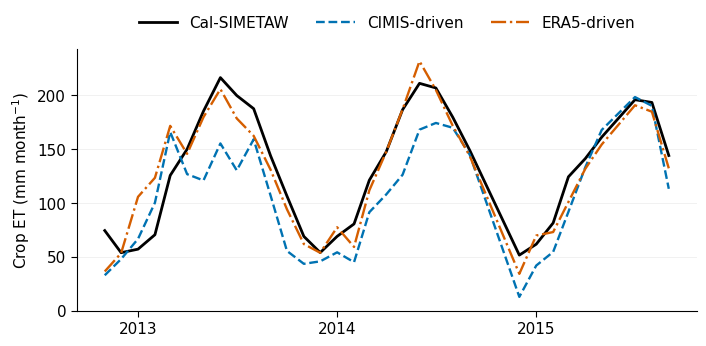

In [14]:

# Figure S8: Monthly PETc comparison: Cal-SIMETAW vs Simulated Scenarios

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8
})

model = pd.read_csv(
    "Evaluation_Output/Combined_ET0_PETc_AETc_AllMethods.csv",
    parse_dates=["Date"]
).set_index("Date").sort_index()

cols = ["PETc_CIMIS", "PETc_PM_ERA5"]

if model.index.duplicated().any():
    raise ValueError("Duplicate dates found in model output.")

month = model.index.to_period("M")
coverage = model[cols].groupby(month).count()
coverage = coverage.div(coverage.index.days_in_month, axis=0)

complete_months = coverage.index[(coverage >= 0.90).all(axis=1)]

monthly = model[cols].resample("ME").sum(min_count=1)
monthly.index = monthly.index.to_period("M")
monthly = monthly.loc[monthly.index.intersection(complete_months)]

cal = pd.read_csv(
    "Data_To_Validate_With/CAL-SIMETAW_Imperial_monthly.csv"
)

cal["Date"] = pd.to_datetime(cal["Date"], errors="coerce")
cal["Month"] = cal["Date"].dt.to_period("M")
cal["ETc_CalSIMETAW"] = pd.to_numeric(
    cal["ETc_CalSIMETAW"], errors="coerce"
)

cal = cal.dropna(subset=["Month"]).set_index("Month").sort_index()

if cal.index.duplicated().any():
    raise ValueError("Duplicate months found in Cal-SIMETAW data.")

df = monthly.join(cal[["ETc_CalSIMETAW"]], how="inner").dropna()
df = df[df.index != pd.Period("2012-10", freq="M")]

print(f"Evaluation period: {df.index.min()} to {df.index.max()}")
print(f"Number of months: {len(df)}")

fig, ax = plt.subplots(figsize=(7.2, 3.6))

dates = df.index.to_timestamp()

ax.plot(
    dates, df["ETc_CalSIMETAW"],
    color="black", linewidth=2.0,
    label="Cal-SIMETAW"
)

ax.plot(
    dates, df["PETc_CIMIS"],
    color="#0072B2", linestyle="--",
    linewidth=1.7, label="CIMIS-driven"
)

ax.plot(
    dates, df["PETc_PM_ERA5"],
    color="#D55E00", linestyle="-.",
    linewidth=1.7, label="ERA5-driven"
)

ax.set_ylabel("Crop ET (mm month$^{-1}$)")
ax.set_ylim(bottom=0)

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

ax.grid(axis="y", alpha=0.2, linewidth=0.6)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False,
    columnspacing=1.8,
    handlelength=2.5
)

ax.tick_params(direction="out", length=4, width=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


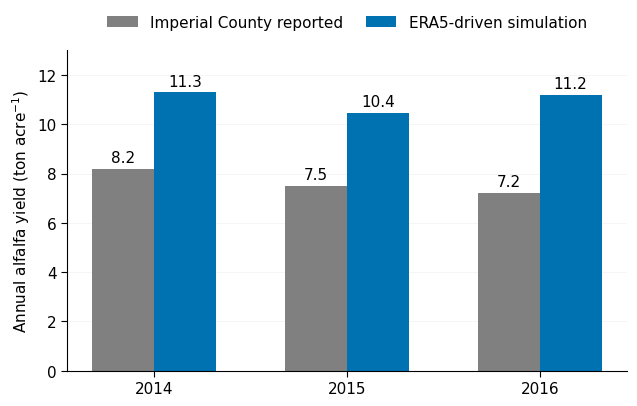

In [15]:

# Figure S10: Validation of Simulated Annual Alfalfa Yield

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.linewidth": 0.8
})

years = ["2014", "2015", "2016"]
reported = np.array([8.2, 7.5, 7.2])
simulated = np.array([25.308, 23.416, 25.063]) * 0.44609

x = np.arange(len(years))
width = 0.32

fig, ax = plt.subplots(figsize=(6.5, 4.2))

bars1 = ax.bar(
    x - width / 2, reported, width,
    color="#808080", label="Imperial County reported"
)

bars2 = ax.bar(
    x + width / 2, simulated, width,
    color="#0072B2", label="ERA5-driven simulation"
)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.15,
            f"{bar.get_height():.1f}",
            ha="center", va="bottom", fontsize=11
        )

ax.set_xticks(x, years)
ax.set_ylabel("Annual alfalfa yield (ton acre$^{-1}$)")
ax.set_ylim(0, 13)

ax.grid(axis="y", alpha=0.15, linewidth=0.6)
ax.set_axisbelow(True)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False,
    columnspacing=1.5
)

ax.tick_params(direction="out", length=4, width=0.8)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()
